JS06 Praktikum 2: Regresi Non-Linier dengan SVR (RBF) - Posisi_gaji.csv.

Memprediksi gaji berdasarkan level posisi, plus prediksi level 6.5.
Metrik dihitung pada skala asli (dolar) maupun skala terstandardisasi
(agar bisa dibandingkan dengan output modul).

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("svr_posisi_gaji.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-regresi\praktikum2


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

BASE = Path(__file__).resolve().parent
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)

dataset = pd.read_csv(BASE.parent / "data" / "Posisi_gaji.csv")
print(dataset.to_string(index=False))
X = dataset.iloc[:, 1:2].values.astype(float)   # Level
y = dataset.iloc[:, 2].values.astype(float)     # Gaji

sc_X, sc_y = StandardScaler(), StandardScaler()
Xs = sc_X.fit_transform(X)
ys = sc_y.fit_transform(y.reshape(-1, 1))

regressor = SVR(kernel="rbf")
regressor.fit(Xs, ys.ravel())

           Posisi  Level    Gaji
 Business Analyst      1   45000
Junior Consultant      2   50000
Senior Consultant      3   60000
          Manager      4   80000
  Country Manager      5  110000
   Region Manager      6  150000
          Partner      7  200000
   Senior Partner      8  300000
          C-level      9  500000
              CEO     10 1000000


,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [3]:
# --- prediksi level 6.5 (skala asli) ---
gaji_prediksi = sc_y.inverse_transform(
    regressor.predict(sc_X.transform(np.array([[6.5]]))).reshape(-1, 1))
print("\nPrediksi gaji level 6.5: %.2f" % gaji_prediksi[0, 0])


Prediksi gaji level 6.5: 170370.02


In [4]:
# --- evaluasi: skala terstandardisasi (seperti modul) ---
y_pred_s = regressor.predict(Xs)
mse_s = mean_squared_error(ys.ravel(), y_pred_s)
print("MAE  (scaled): %.6f" % mean_absolute_error(ys.ravel(), y_pred_s))
print("MSE  (scaled): %.6f" % mse_s)
print("RMSE (scaled): %.6f" % np.sqrt(mse_s))
print("R2   (scaled): %.6f" % r2_score(ys.ravel(), y_pred_s))

MAE  (scaled): 0.222993
MSE  (scaled): 0.248400
RMSE (scaled): 0.498397
R2   (scaled): 0.751600


In [5]:
# --- evaluasi: skala asli (dolar) ---
y_pred = sc_y.inverse_transform(y_pred_s.reshape(-1, 1)).ravel()
mse = mean_squared_error(y, y_pred)
print("MAE  (rupiah/dolar): %.2f" % mean_absolute_error(y, y_pred))
print("MSE  : %.2f" % mse)
print("RMSE : %.2f" % np.sqrt(mse))
print("R2   : %.6f" % r2_score(y, y_pred))

MAE  (rupiah/dolar): 63332.39
MSE  : 20036494264.13
RMSE : 141550.32
R2   : 0.751600


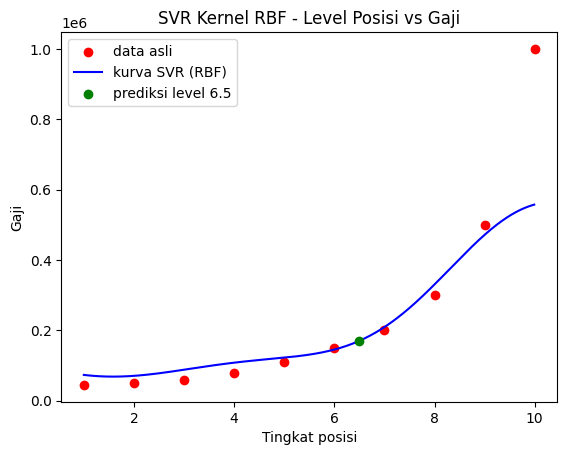

In [6]:
# --- visualisasi kurva SVR pada skala asli ---
grid = np.arange(X.min(), X.max(), 0.01).reshape(-1, 1)
grid_pred = sc_y.inverse_transform(
    regressor.predict(sc_X.transform(grid)).reshape(-1, 1)).ravel()
plt.scatter(X, y, color="red", label="data asli")
plt.plot(grid, grid_pred, color="blue", label="kurva SVR (RBF)")
plt.scatter([6.5], [gaji_prediksi[0, 0]], color="green", zorder=5,
            label="prediksi level 6.5")
plt.title("SVR Kernel RBF - Level Posisi vs Gaji")
plt.xlabel("Tingkat posisi")
plt.ylabel("Gaji")
plt.legend()
plt.savefig(OUT / "svr_posisi_gaji.png", dpi=130, bbox_inches="tight")

pd.DataFrame({"level": X.ravel(), "gaji_aktual": y, "gaji_prediksi": y_pred}) \
    .to_csv(OUT / "prediksi_svr.csv", index=False)

In [7]:
# cek: prediksi 6.5 di antara gaji level 6 dan 7 (monoton naik)
lo, hi = y_pred[5], y_pred[6]
assert lo <= gaji_prediksi[0, 0] <= hi, (lo, gaji_prediksi[0, 0], hi)
print("[OK] prediksi 6.5 berada di antara prediksi level 6 dan 7")

[OK] prediksi 6.5 berada di antara prediksi level 6 dan 7
